In [23]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv

load_dotenv()

True

In [24]:
model = ChatGroq(model="openai/gpt-oss-20b")

In [25]:
class BlogState(TypedDict):
    topic: str
    outline: str
    blog: str
    evaluate : int

In [26]:
def create_outline(state: BlogState) -> BlogState:
        topic = state['topic']

        prompt = f"""Generate an outline for this Particular Topic
        {topic}
        """

        outline = model.invoke(prompt).content

        state['outline'] = outline
    
        return state

In [27]:
def create_blog(state: BlogState) -> BlogState:
        topic = state['topic']
        
        outline = state['outline']

        prompt = f"""Generate a Comprehensive Blog on the topic {topic} Using the following Outline
        {outline}
        """
        # prompt = f"""Generate a Comprehensive Blog using the following Outline
        # {outline}
        # """
        Blog = model.invoke(prompt).content

        state['blog'] = Blog
    
        return state

In [28]:
def Evaluate(state: BlogState) -> BlogState:
        outline = state['outline']

        blog = state['blog']

        # prompt = f"""Based on this outline {outline} rate my blog {blog} and generate a score in integer. 
        # """
        prompt = f"""You are an expert content evaluator. Your task is to score how well a blog post follows its provided outline. 

        Evaluate the alignment based on topic coverage, structural flow, and relevance. 
        Score the alignment on a scale of 1 to 100, where 100 means the blog perfectly matches the outline, and 1 means it completely deviates.

        Return ONLY the integer score. Do not output any other text, reasoning, punctuation, or formatting.

        Outline:
        ---
        {outline}
        ---

        Blog Post:
        ---
        {blog}
        ---
        """

        
        evaluate = model.invoke(prompt).content

        state['evaluate'] = evaluate
    
        return state

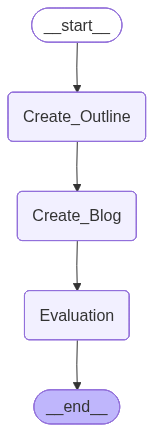

In [29]:
graph = StateGraph(BlogState)
#node
graph.add_node('Create_Outline', create_outline)

graph.add_node('Create_Blog', create_blog)

graph.add_node('Evaluation', Evaluate)

graph.add_edge(START, 'Create_Outline')

graph.add_edge('Create_Outline', 'Create_Blog')

graph.add_edge('Create_Blog', 'Evaluation')

graph.add_edge('Evaluation', END)

PC_workflow = graph.compile()

PC_workflow

In [30]:
input_state = {'topic': "ML"}

final_state = PC_workflow.invoke(input_state)

print(final_state)

{'topic': 'ML', 'outline': '**Outline: Machine Learning (ML)**  \n*(A comprehensive, modular framework suitable for a textbook, course syllabus, or research survey)*  \n\n---\n\n### 1. Introduction  \n1.1. What is Machine Learning?  \n1.2. ML vs. Traditional Programming  \n1.3. Historical Milestones (1950s‑present)  \n1.4. Interdisciplinary Roots (statistics, computer science, neuroscience, cognitive science)  \n1.5. Applications & Impact (industry, academia, everyday life)\n\n---\n\n### 2. Foundations of Machine Learning  \n2.1. Problem Formulation  \n&nbsp;&nbsp;&nbsp;&nbsp;2.1.1. Input–Output Mapping  \n&nbsp;&nbsp;&nbsp;&nbsp;2.1.2. Loss Functions & Optimization Goals  \n2.2. Data: Types, Quality, and Preprocessing  \n&nbsp;&nbsp;&nbsp;&nbsp;2.2.1. Structured vs. Unstructured Data  \n&nbsp;&nbsp;&nbsp;&nbsp;2.2.2. Feature Engineering & Representation Learning  \n&nbsp;&nbsp;&nbsp;&nbsp;2.2.3. Data Augmentation & Imputation  \n2.3. Statistical Learning Theory  \n&nbsp;&nbsp;&nbsp;&n

In [31]:
print(final_state['topic'])

ML


In [32]:
print(final_state['outline'])

**Outline: Machine Learning (ML)**  
*(A comprehensive, modular framework suitable for a textbook, course syllabus, or research survey)*  

---

### 1. Introduction  
1.1. What is Machine Learning?  
1.2. ML vs. Traditional Programming  
1.3. Historical Milestones (1950s‑present)  
1.4. Interdisciplinary Roots (statistics, computer science, neuroscience, cognitive science)  
1.5. Applications & Impact (industry, academia, everyday life)

---

### 2. Foundations of Machine Learning  
2.1. Problem Formulation  
&nbsp;&nbsp;&nbsp;&nbsp;2.1.1. Input–Output Mapping  
&nbsp;&nbsp;&nbsp;&nbsp;2.1.2. Loss Functions & Optimization Goals  
2.2. Data: Types, Quality, and Preprocessing  
&nbsp;&nbsp;&nbsp;&nbsp;2.2.1. Structured vs. Unstructured Data  
&nbsp;&nbsp;&nbsp;&nbsp;2.2.2. Feature Engineering & Representation Learning  
&nbsp;&nbsp;&nbsp;&nbsp;2.2.3. Data Augmentation & Imputation  
2.3. Statistical Learning Theory  
&nbsp;&nbsp;&nbsp;&nbsp;2.3.1. Bias–Variance Trade‑off  
&nbsp;&nbsp;&n

In [33]:
print(final_state['blog'])

# Machine Learning Unpacked  
*A modular, textbook‑style guide that can double as a course syllabus, a research survey, or a deep‑dive blog post.*

---

## 1. Introduction  

### 1.1 What is Machine Learning?  
At its core, Machine Learning (ML) is the art of letting computers **learn** from data instead of being explicitly programmed for every possible situation. Think of a child who learns to recognize a dog after seeing a few pictures—ML algorithms mimic that process, adjusting internal parameters to minimize prediction error.

### 1.2 ML vs. Traditional Programming  
| Traditional Programming | Machine Learning |
|------------------------|-----------------|
| Rules are hand‑crafted by a developer | Rules are inferred from data |
| Works well when the problem space is fully understood | Excels in high‑dimensional, noisy, or partially understood domains |
| Hard to scale to new data | Naturally adapts as more data arrives |

### 1.3 Historical Milestones (1950s‑present)  
| Era | Mil

In [34]:
print(final_state['evaluate'])

48
